# 04. Final evaluation on the test set

## Objective

This notebook evaluates the final configurations selected in
`03_modelling.ipynb` on the reserved 20% test split. At 10% and 20%
contact capacity, it reports how many customers with recorded churn
each method places in the contact list, along with recall and lift.
It also interprets the fitted models.

## Inputs

- Development dataset (80% split): `churn-bigml-80.csv`
- Test dataset (20% split): `churn-bigml-20.csv`
- Decision files: `audit_decisions.json`, `eda_decisions.json` and
  `modelling_decisions.json`

## Procedure

1. Check that both files have the required predictor and target columns.
2. Fit each version of Logistic Regression and Random Forest once on
   the full development set using the saved settings. Apply the fixed
   thresholds for each version of the rule-based approach.
3. Rank test customers and report the number selected, the number with
   recorded churn, recall and lift at both contact capacities. Evaluate
   random selection using repeated random orderings and use the same
   random baseline for both versions.
4. Estimate uncertainty using paired bootstrap resampling of test
   customers. In each replicate, use the same resampled customers for
   the methods being compared, reapply the contact limits and recompute
   the metrics. The fitted models and rule thresholds stay fixed.
5. Interpret the fitted models using SHAP and permutation feature
   importance.

The model-based and rule-based comparisons include the main version
and the sensitivity version without `Customer service calls`.

## Test-set policy

During the data audit, the test split was used for structure and
overlap checks. It was reserved for performance evaluation until the
model settings and rule thresholds were fixed in `03_modelling.ipynb`.
Test results are used for reporting performance and uncertainty.
All settings remain fixed throughout the evaluation.

## 1. Setup and data loading

In [1]:
# === 1.1 Project location and decision files ===
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd

# Locate the project in Colab or in a local Jupyter session.
if "COLAB_RELEASE_TAG" in os.environ:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/bda-churn-capstone")
else:
    working_dir = Path.cwd()
    PROJECT = working_dir.parent if working_dir.name == "notebooks" else working_dir

processed_dir = PROJECT / "data" / "processed"
decision_paths = {
    "audit": processed_dir / "audit_decisions.json",
    "eda": processed_dir / "eda_decisions.json",
    "modelling": processed_dir / "modelling_decisions.json",
}

decisions = {}
for name, path in decision_paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"Required decision file not found: {path}")

    with path.open(encoding="utf-8") as file:
        decisions[name] = json.load(file)

audit_decisions = decisions["audit"]
eda_decisions = decisions["eda"]
modelling_decisions = decisions["modelling"]
selected_settings = modelling_decisions["selected_settings"]

RANDOM_SEED = int(modelling_decisions["random_seed"])
CONTACT_CAPACITIES = tuple(modelling_decisions["contact_capacities"])

if CONTACT_CAPACITIES != (0.10, 0.20):
    raise ValueError(f"Expected contact capacities of 10% and 20%, got {CONTACT_CAPACITIES}.")

if modelling_decisions["capacity_rounding"] != "floor":
    raise ValueError("Expected floor rounding for contact capacities.")

loaded_files = ", ".join(path.name for path in decision_paths.values())
print(f"Project path: {PROJECT}")
print(f"Loaded decision files: {loaded_files}")
print(f"Random seed: {RANDOM_SEED}")
print(f"Contact capacities: {', '.join(f'{c:.0%}' for c in CONTACT_CAPACITIES)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project path: /content/drive/MyDrive/bda-churn-capstone
Loaded decision files: audit_decisions.json, eda_decisions.json, modelling_decisions.json
Random seed: 42
Contact capacities: 10%, 20%


In [2]:
# === 1.2 Load and validate the development and test data ===
raw_dir = PROJECT / "data" / "raw"
dev_path = raw_dir / audit_decisions["development_file"]
test_path = raw_dir / audit_decisions["test_file"]

for path in (dev_path, test_path):
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

dev = pd.read_csv(dev_path)
test = pd.read_csv(test_path)

target = audit_decisions["target"]
initial_features = eda_decisions["initial_features"]
categorical_cols = initial_features["categorical"]
numeric_cols = initial_features["numeric"]
excluded_cols = initial_features["excluded"]
feature_cols = categorical_cols + numeric_cols

configured_cols = feature_cols + excluded_cols + [target]
expected_cols = set(configured_cols)

if len(expected_cols) != len(configured_cols):
    raise ValueError("Feature lists contain duplicates, overlap or include the target.")

for name, data, expected_rows in (
    ("Development", dev, 2666),
    ("Test", test, 667),
):
    actual_cols = set(data.columns)
    missing = expected_cols - actual_cols
    unexpected = actual_cols - expected_cols

    if missing or unexpected:
        raise ValueError(
            f"{name} columns differ from the EDA configuration. "
            f"Missing: {sorted(missing)}. Unexpected: {sorted(unexpected)}."
        )

    if len(data) != expected_rows:
        raise ValueError(
            f"{name}: expected {expected_rows:,} records, found {len(data):,}."
        )

print(f"Development file: {dev_path.name} ({len(dev):,} records)")
print(f"Test file: {test_path.name} ({len(test):,} records)")
print(f"Both files have the expected {len(expected_cols)} columns.")

Development file: churn-bigml-80.csv (2,666 records)
Test file: churn-bigml-20.csv (667 records)
Both files have the expected 20 columns.


In [3]:
# === 1.3 Predictors, target and output folders ===
def encode_target(series):
    """Encode the binary target as 0 (no churn) and 1 (churn)."""
    labels = series.astype("string").str.strip().str.lower()
    encoded = labels.map({"false": 0, "true": 1, "0": 0, "1": 1})

    if encoded.isna().any() or encoded.nunique() != 2:
        raise ValueError("Expected a complete binary target with both classes.")

    return encoded.astype(int).rename(series.name)


X_dev, y_dev = dev[feature_cols].copy(), encode_target(dev[target])
X_test, y_test = test[feature_cols].copy(), encode_target(test[target])

# Report categories present only in the test split.
for col in categorical_cols:
    development_categories = set(X_dev[col].dropna().unique())
    test_categories = set(X_test[col].dropna().unique())
    unseen = test_categories - development_categories

    if unseen:
        print(f"Note: {col} has unseen test categories: {sorted(unseen, key=str)}")

FIGURES = PROJECT / "reports" / "figures"
TABLES = PROJECT / "reports" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print(f"Development: churn {y_dev.sum():,} of {len(y_dev):,} ({y_dev.mean():.1%})")
print(f"Test: churn {y_test.sum():,} of {len(y_test):,} ({y_test.mean():.1%})")
print(f"Initial predictors: {len(feature_cols)}")

for capacity in CONTACT_CAPACITIES:
    n_contacts = int(np.floor(capacity * len(X_test)))
    print(f"Test contacts at {capacity:.0%}: {n_contacts}")

Development: churn 388 of 2,666 (14.6%)
Test: churn 95 of 667 (14.2%)
Initial predictors: 15
Test contacts at 10%: 66
Test contacts at 20%: 133


The test split has a churn rate similar to the development set (14.2%
versus 14.6%). At 10% capacity, 66 test customers can be contacted.
Because the test set contains 95 customers with recorded churn, the
maximum achievable recall at this capacity is 66/95 = 69.5%. At 20%
capacity, 133 contacts exceed the number of churners, so the maximum
achievable recall is 100%.

## 2. Shared evaluation and modelling functions

This notebook reuses the evaluation and ranking logic from
`03_modelling.ipynb`, including the contact limits, recall and lift
calculations, and seeded tie-breaking rules. The rule-based approach
uses the thresholds saved in `modelling_decisions.json`.

The model pipelines use the same feature selection and preprocessing
as in cross-validation, with the final settings loaded from
`modelling_decisions.json`. Each pipeline is fitted on the development
data. The functions below are defined in this notebook so it can run
independently of `03_modelling.ipynb`.

In [4]:
# === 2.1 Contact limits, recall and lift, ranking ===
from math import floor


def evaluate_at_capacities(y_true, ranked_positions, capacities=CONTACT_CAPACITIES):
    """Evaluate a ranked customer list at each contact capacity."""
    labels = np.asarray(y_true)
    ranking = np.asarray(ranked_positions)

    if labels.ndim != 1 or not np.isin(labels, [0, 1]).all():
        raise ValueError("y_true must be a one-dimensional array of binary labels.")

    n_customers = len(labels)
    if (
        ranking.shape != (n_customers,)
        or not np.issubdtype(ranking.dtype, np.integer)
        or not np.array_equal(np.sort(ranking), np.arange(n_customers))
    ):
        raise ValueError("Ranking must contain every position exactly once.")

    total_churners = int(labels.sum())
    if total_churners == 0:
        raise ValueError("Recall and lift require at least one churner.")

    churn_rate = total_churners / n_customers
    results = []

    for capacity in capacities:
        n_selected = floor(capacity * n_customers)
        if not 1 <= n_selected <= n_customers:
            raise ValueError(f"Invalid contact count at capacity {capacity:.0%}.")

        churners_selected = int(labels[ranking[:n_selected]].sum())
        results.append({
            "capacity": capacity,
            "n_selected": n_selected,
            "churners_selected": churners_selected,
            "recall": churners_selected / total_churners,
            "lift": (churners_selected / n_selected) / churn_rate,
        })

    return pd.DataFrame(results)


def rank_positions(sort_keys, seed=RANDOM_SEED):
    """Rank positions by descending keys, with seeded random tie-breaking."""
    keys = [np.asarray(key, dtype=float) for key in sort_keys]

    if not keys or keys[0].ndim != 1:
        raise ValueError("Provide at least one one-dimensional sort key.")

    n_customers = len(keys[0])
    if any(key.shape != (n_customers,) for key in keys):
        raise ValueError("All sort keys must be one-dimensional and of equal length.")

    if any(not np.isfinite(key).all() for key in keys):
        raise ValueError("Sort keys must contain only finite values.")

    random_key = np.random.default_rng(seed).random(n_customers)

    # lexsort gives the last key highest priority. Negation sorts descending.
    descending_keys = [-key for key in reversed(keys)]
    return np.lexsort([random_key, *descending_keys])


# Use the test labels to check the theoretical recall ceiling.
perfect_ranking = np.argsort(-y_test.to_numpy(), kind="stable")
display(evaluate_at_capacities(y_test, perfect_ranking).round(3))

,capacity,n_selected,churners_selected,recall,lift
0,0.1,66,66,0.695,7.021
1,0.2,133,95,1.000,5.015


In [5]:
# === 2.2 Feature sets and model pipelines ===
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

LR_FIXED = modelling_decisions["logistic_regression_fixed_settings"]
RF_FIXED = modelling_decisions["random_forest_fixed_settings"]


def select_features(state_handling, voicemail_features, drop_service_calls=False):
    """Return the categorical and numeric columns for one feature set."""
    removed = set()

    if state_handling == "exclude":
        removed.add("State")

    if voicemail_features == "plan_only":
        removed.add("Number vmail messages")
    elif voicemail_features == "messages_only":
        removed.add("Voice mail plan")

    if drop_service_calls:
        removed.add("Customer service calls")

    selected_categorical = [col for col in categorical_cols if col not in removed]
    selected_numeric = [col for col in numeric_cols if col not in removed]

    return selected_categorical, selected_numeric


def build_model(model_name, version):
    """Build an unfitted pipeline from the saved final settings."""
    settings = selected_settings[model_name][version]
    selected_categorical, selected_numeric = select_features(
        settings["state_handling"],
        settings["voicemail_features"],
        drop_service_calls=(version == "without_service_calls"),
    )

    if model_name == "logistic_regression":
        numeric_step = StandardScaler()
        lr_settings = {**LR_FIXED, "C": settings["C"]}
        model = LogisticRegression(**lr_settings)
    elif model_name == "random_forest":
        numeric_step = "passthrough"
        rf_settings = {
            "random_state": RANDOM_SEED,
            "n_jobs": -1,
            **RF_FIXED,
            "min_samples_leaf": settings["min_samples_leaf"],
        }
        model = RandomForestClassifier(**rf_settings)
    else:
        raise ValueError(f"Unknown model: {model_name}")

    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), selected_categorical),
        ("numeric", numeric_step, selected_numeric),
    ])

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", model),
    ])


# Inspect the four configurations before fitting.
for model_name in ("logistic_regression", "random_forest"):
    for version in ("main", "without_service_calls"):
        estimator = build_model(model_name, version).named_steps["model"]
        print(f"{model_name:<20} {version:<22} {estimator}")

logistic_regression  main                   LogisticRegression(C=0.1, max_iter=5000)
logistic_regression  without_service_calls  LogisticRegression(C=0.1, max_iter=5000)
random_forest        main                   RandomForestClassifier(n_jobs=-1, random_state=42)
random_forest        without_service_calls  RandomForestClassifier(min_samples_leaf=5, n_jobs=-1, random_state=42)


In [6]:
# === 2.3 Rule-based ranking ===
def rank_by_rule(features, day_minutes_threshold, service_calls_threshold=None):
    """Rank customers by rule score, daytime minutes and seeded tie-breaking."""
    day_minutes = features["Total day minutes"].to_numpy(dtype=float)
    international_plan = (
        features["International plan"]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    if not international_plan.isin(["yes", "no"]).all():
        raise ValueError("International plan must contain only Yes or No.")

    scores = international_plan.eq("yes").to_numpy(dtype=int)
    scores += day_minutes >= day_minutes_threshold

    if service_calls_threshold is not None:
        service_calls = features["Customer service calls"].to_numpy(dtype=float)

        if not np.isfinite(service_calls).all():
            raise ValueError("Customer service calls must contain finite values.")

        scores += service_calls >= service_calls_threshold

    return rank_positions([scores, day_minutes])


for version, settings in selected_settings["rule"].items():
    service_calls_threshold = settings["service_calls_threshold"]
    service_condition = (
        "not used"
        if service_calls_threshold is None
        else f">= {service_calls_threshold}"
    )

    print(
        f"Rule ({version}): service calls {service_condition}, "
        f"day minutes >= {settings['day_minutes_threshold']:.3f}"
    )

Rule (main): service calls >= 5, day minutes >= 269.775
Rule (without_service_calls): service calls not used, day minutes >= 269.775


### Checks

Ranking the test customers by their observed churn labels reproduced
the theoretical recall ceilings of 69.5% at 10% contact capacity and
100% at 20% contact capacity. This check verifies the contact counts
and recall calculation for a perfect ranking.

Four unfitted model pipelines were built from the settings in
`modelling_decisions.json`, and the saved thresholds for both rule
variants were displayed. The Random Forest seed was fixed at 42.

The next section fits the models on the full development set and
evaluates the fitted models and baselines on the test set.

## 3. Test-set evaluation

Each version of Logistic Regression and Random Forest is fitted once
on the full development set using the saved settings. Test customers
are ranked by predicted churn probability, with ties resolved using
the procedure in Section 2. Each ranking is evaluated at 10% and 20%
contact capacity.

The rule-based approach uses the saved thresholds. The daytime usage
threshold was calculated on the full development set using the selected
percentile. The random baseline uses 1,000 random orderings of the test
customers with seed 42 and is shared by both versions.

For each method and version, the results table reports the number of
customers selected for contact, the number with recorded churn among
them, recall and lift. For random selection, the churn count, recall
and lift are averaged across the 1,000 orderings. Average Precision and
ROC-AUC are reported for each version of Logistic Regression and
Random Forest.

The test scores of each method are retained in memory, so that the
bootstrap analysis in Section 4 can re-rank resampled customers without
refitting the models. The evaluation tables are saved as CSV files.

In [7]:
# === 3.1 Fit the final models and score the test customers ===
VERSIONS = ("main", "without_service_calls")
MODEL_NAMES = {
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest",
}

# Sort keys per method and version, reused by the bootstrap in Section 4.
test_sort_keys = {}
test_results = []
ranking_quality = []

for model_name, method in MODEL_NAMES.items():
    for version in VERSIONS:
        pipeline = build_model(model_name, version)
        pipeline.fit(X_dev, y_dev)
        scores = pipeline.predict_proba(X_test)[:, 1]

        test_sort_keys[(method, version)] = [scores]
        ranking = rank_positions([scores])

        test_results.append(
            evaluate_at_capacities(y_test, ranking).assign(method=method, version=version)
        )
        ranking_quality.append({
            "method": method,
            "version": version,
            "average_precision": average_precision_score(y_test, scores),
            "roc_auc": roc_auc_score(y_test, scores),
        })

ranking_quality = pd.DataFrame(ranking_quality)
display(ranking_quality.round(3))
print(f"Fitted and scored {len(ranking_quality)} model versions.")

,method,version,average_precision,roc_auc
0,Logistic Regression,main,0.436,0.824
1,Logistic Regression,without_service_calls,0.406,0.739
2,Random Forest,main,0.871,0.928
3,Random Forest,without_service_calls,0.704,0.824


Fitted and scored 4 model versions.


In [8]:
# === 3.2 Rule-based approach and random selection on the test set ===
baseline_test_results = []


def rule_scores(features, day_minutes_threshold, service_calls_threshold=None):
    """Return the first ranking key for the rule-based approach."""
    plan = features["International plan"].astype("string").str.strip().str.casefold()
    day_minutes = features["Total day minutes"].to_numpy(dtype=float)

    scores = plan.eq("yes").to_numpy(dtype=int)
    scores += day_minutes >= day_minutes_threshold

    if service_calls_threshold is not None:
        service_calls = features["Customer service calls"].to_numpy(dtype=float)
        scores += service_calls >= service_calls_threshold

    return scores


day_minutes_test = X_test["Total day minutes"].to_numpy(dtype=float)

for version in VERSIONS:
    settings = selected_settings["rule"][version]
    threshold = settings["day_minutes_threshold"]
    k = settings["service_calls_threshold"]

    ranking = rank_by_rule(X_test, threshold, k)
    sort_keys = [rule_scores(X_test, threshold, k), day_minutes_test]

    # Check that the keys retained for the bootstrap reproduce the ranking.
    if not np.array_equal(rank_positions(sort_keys), ranking):
        raise ValueError(f"Rule sort keys do not reproduce the {version} ranking.")

    test_sort_keys[("Rule-based", version)] = sort_keys
    baseline_test_results.append(
        evaluate_at_capacities(y_test, ranking).assign(
            method="Rule-based",
            version=version,
        )
    )

# Use the saved number of random orderings for the shared baseline.
N_RANDOM_ORDERINGS = int(modelling_decisions["random_selection"]["n_orderings"])
random_rng = np.random.default_rng(RANDOM_SEED)

random_runs = pd.concat(
    [
        evaluate_at_capacities(y_test, random_rng.permutation(len(y_test)))
        for _ in range(N_RANDOM_ORDERINGS)
    ],
    ignore_index=True,
)

random_test = (
    random_runs.groupby("capacity", as_index=False)
    .agg(
        n_selected=("n_selected", "first"),
        churners_selected=("churners_selected", "mean"),
        recall=("recall", "mean"),
        lift=("lift", "mean"),
        recall_p2_5=("recall", lambda values: values.quantile(0.025)),
        recall_p97_5=("recall", lambda values: values.quantile(0.975)),
    )
)

capacity_columns = ["capacity", "n_selected", "churners_selected", "recall", "lift"]
baseline_test_results.append(
    random_test[capacity_columns].assign(
        method="Random selection",
        version="shared",
    )
)

display(random_test.round(3))
print(f"Random orderings evaluated: {N_RANDOM_ORDERINGS:,}")

,capacity,n_selected,churners_selected,recall,lift,recall_p2_5,recall_p97_5
0,0.1,66,9.333,0.098,0.993,0.053,0.147
1,0.2,133,18.938,0.199,1.000,0.137,0.274


Random orderings evaluated: 1,000


In [9]:
# === 3.3 Test-set results table ===
METHOD_ORDER = [
    "Random selection",
    "Rule-based",
    "Logistic Regression",
    "Random Forest",
]
VERSION_ORDER = ["shared", "main", "without_service_calls"]

test_results_long = pd.concat(
    [*test_results, *baseline_test_results],
    ignore_index=True,
)

test_results_long = test_results_long.merge(
    ranking_quality,
    on=["method", "version"],
    how="left",
    validate="many_to_one",
)

# Expect three methods with two versions each, plus one shared random baseline.
result_keys = ["method", "version", "capacity"]
expected_rows = (3 * len(VERSIONS) + 1) * len(CONTACT_CAPACITIES)

if len(test_results_long) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows} test result rows, found {len(test_results_long)}."
    )

if test_results_long.duplicated(result_keys).any():
    raise ValueError("Duplicate results for a method, version and capacity.")

# AP and ROC-AUC must be present for both versions of each fitted model.
model_rows = test_results_long["method"].isin(MODEL_NAMES.values())
quality_columns = ["average_precision", "roc_auc"]

if test_results_long.loc[model_rows, quality_columns].isna().any().any():
    raise ValueError("Missing Average Precision or ROC-AUC for a fitted model.")

test_results_long["method"] = pd.Categorical(
    test_results_long["method"],
    categories=METHOD_ORDER,
    ordered=True,
)
test_results_long["version"] = pd.Categorical(
    test_results_long["version"],
    categories=VERSION_ORDER,
    ordered=True,
)
test_results_long = test_results_long.sort_values(
    ["version", "capacity", "method"]
).reset_index(drop=True)

# Maximum achievable recall at each contact capacity.
total_test_churners = int(y_test.sum())
test_results_long["recall_ceiling"] = (
    np.minimum(test_results_long["n_selected"], total_test_churners)
    / total_test_churners
)

display_columns = [
    "version",
    "capacity",
    "method",
    "n_selected",
    "churners_selected",
    "recall",
    "recall_ceiling",
    "lift",
    "average_precision",
    "roc_auc",
]

display(test_results_long[display_columns].round(3))

test_results_path = TABLES / "final_test_results.csv"
test_results_long[display_columns].to_csv(test_results_path, index=False)
print(f"Saved {test_results_path.relative_to(PROJECT)}")

,version,capacity,method,n_selected,churners_selected,recall,recall_ceiling,lift,average_precision,roc_auc
0,shared,0.1,Random selection,66,9.333,0.098,0.695,0.993,NaN,NaN
1,shared,0.2,Random selection,133,18.938,0.199,1.000,1.000,NaN,NaN
2,main,0.1,Rule-based,66,33.000,0.347,0.695,3.511,NaN,NaN
3,main,0.1,Logistic Regression,66,31.000,0.326,0.695,3.298,0.436,0.824
4,main,0.1,Random Forest,66,63.000,0.663,0.695,6.702,0.871,0.928
5,main,0.2,Rule-based,133,63.000,0.663,1.000,3.326,NaN,NaN
6,main,0.2,Logistic Regression,133,53.000,0.558,1.000,2.798,0.436,0.824
7,main,0.2,Random Forest,133,82.000,0.863,1.000,4.329,0.871,0.928
8,without_service_calls,0.1,Rule-based,66,32.000,0.337,0.695,3.404,NaN,NaN
9,without_service_calls,0.1,Logistic Regression,66,35.000,0.368,0.695,3.723,0.406,0.739


Saved reports/tables/final_test_results.csv


### Test-set findings

**Main comparison.** At 10% contact capacity (66 customers), Random
Forest achieved the highest recall, identifying 63 of the 95 customers
with recorded churn (recall 66.3%, lift 6.7). This was close to the
maximum achievable recall of 69.5% at this capacity. At 20% capacity
(133 customers), Random Forest again achieved the highest recall,
identifying 82 of the 95 customers with recorded churn (recall 86.3%,
lift 4.3).

At 10% and 20% capacity, respectively, recall was 34.7% and 66.3% for
the rule-based baseline, and 32.6% and 55.8% for Logistic Regression.
Mean recall across the random orderings was 9.8% and 19.9%.

**Sensitivity to `Customer service calls`.** After removing this
feature, the models and rule were tuned separately on the development
set. On the test set, Random Forest recall fell from 66.3% to 57.9%
at 10% capacity and from 86.3% to 66.3% at 20% capacity. Logistic
Regression recall rose from 32.6% to 36.8% and from 55.8% to 57.9%,
respectively. Recall for the rule-based baseline fell from 34.7% to
33.7% and from 66.3% to 57.9%. Random Forest achieved the highest
recall at both capacities among the versions without the feature.
Section 4 uses paired bootstrap resampling to assess uncertainty in
the observed differences.

**Overall ranking performance.** The main Random Forest achieved an
Average Precision of 0.87 and a ROC-AUC of 0.93 on the test set. The
main Logistic Regression achieved 0.44 and 0.82, respectively.

## 4. Bootstrap uncertainty

The test set contains 95 customers with recorded churn. On this test
set, identifying one additional customer with recorded churn changes
recall by about 1.1 percentage points. A paired bootstrap is used to
estimate uncertainty in test-set recall and in differences between
methods.

In each of 2,000 replicates, 667 test records are sampled with
replacement. The same sampled rows are used for both versions of
Logistic Regression, Random Forest and the rule-based approach.
Customers are re-ranked within each replicate using the stored
ranking keys and the tie-breaking procedure from Section 2.
The 10% and 20% contact limits are reapplied, and recall is
calculated using the number of churn records in that replicate.
The fitted models and rule thresholds stay fixed. The random
selection results are reported in Section 3.

For each method, version and capacity, the 2.5th and 97.5th
percentiles of the bootstrap recall values form a 95% percentile
interval. Paired recall differences are computed within each
replicate before taking the same percentiles. The comparisons are:

- Random Forest minus the rule-based approach and Random Forest
  minus Logistic Regression, separately for each version.
- The main version minus the version without `Customer service calls`,
  separately for each method.

An interval entirely above zero favours the first method or version
in the comparison. An interval entirely below zero favours the second.
These intervals reflect test-sample variability with the fitted models
and rule thresholds held fixed.

In [10]:
# === 4.1 Paired bootstrap of the test set ===
from time import perf_counter

N_BOOTSTRAP = 2000

expected_keys = {
    (method, version)
    for method in ("Rule-based", "Logistic Regression", "Random Forest")
    for version in VERSIONS
}

actual_keys = set(test_sort_keys)
missing_keys = expected_keys - actual_keys
unexpected_keys = actual_keys - expected_keys

if missing_keys or unexpected_keys:
    raise ValueError(
        f"Unexpected bootstrap inputs. Missing: {sorted(missing_keys)}. "
        f"Unexpected: {sorted(unexpected_keys)}."
    )

bootstrap_rng = np.random.default_rng(RANDOM_SEED)
y_test_array = y_test.to_numpy()
n_test = len(y_test_array)
bootstrap_rows = []
start_time = perf_counter()

for replicate in range(N_BOOTSTRAP):
    sample = bootstrap_rng.integers(0, n_test, size=n_test)
    y_sample = y_test_array[sample]

    # Reuse the same sampled rows for every method and version.
    for (method, version), sort_keys in test_sort_keys.items():
        sample_keys = [np.asarray(key)[sample] for key in sort_keys]
        ranking = rank_positions(sample_keys)
        results = evaluate_at_capacities(y_sample, ranking)

        for capacity, recall in zip(results["capacity"], results["recall"]):
            bootstrap_rows.append((replicate, method, version, capacity, recall))

bootstrap_recall = pd.DataFrame(
    bootstrap_rows,
    columns=["replicate", "method", "version", "capacity", "recall"],
)

expected_rows = N_BOOTSTRAP * len(expected_keys) * len(CONTACT_CAPACITIES)
if len(bootstrap_recall) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows:,} bootstrap rows, "
        f"found {len(bootstrap_recall):,}."
    )

print(f"Bootstrap replicates: {N_BOOTSTRAP:,}")
print(f"Bootstrap recall rows: {len(bootstrap_recall):,}")
print(f"Finished in {perf_counter() - start_time:.0f} seconds.")

Bootstrap replicates: 2,000
Bootstrap recall rows: 24,000
Finished in 22 seconds.


In [11]:
# === 4.2 Percentile intervals for recall and paired differences ===
def percentile_interval(values):
    """Return the 2.5th and 97.5th percentiles."""
    return pd.Series({
        "ci_low": values.quantile(0.025),
        "ci_high": values.quantile(0.975),
    })


# Pair recall values within each bootstrap replicate and capacity.
wide = bootstrap_recall.pivot(
    index=["replicate", "capacity"],
    columns=["method", "version"],
    values="recall",
)

expected_shape = (
    N_BOOTSTRAP * len(CONTACT_CAPACITIES),
    len(test_sort_keys),
)
if wide.shape != expected_shape:
    raise ValueError(
        f"Expected bootstrap table shape {expected_shape}, found {wide.shape}."
    )

if wide.isna().any().any():
    raise ValueError("Missing recall values in the paired bootstrap results.")

# Observed test recall from Section 3.
observed = (
    test_results_long.loc[test_results_long["method"] != "Random selection"]
    .astype({"method": str, "version": str})
    .set_index(["method", "version", "capacity"])["recall"]
)
observed_wide = observed.unstack(["method", "version"])

recall_intervals = (
    bootstrap_recall.groupby(["method", "version", "capacity"])["recall"]
    .apply(percentile_interval)
    .unstack()
)
recall_intervals.insert(
    0,
    "observed_recall",
    observed.reindex(recall_intervals.index),
)

comparisons = []

for version in VERSIONS:
    for other in ("Rule-based", "Logistic Regression"):
        comparisons.append((
            f"Random Forest minus {other} ({version})",
            ("Random Forest", version),
            (other, version),
        ))

for method in ("Rule-based", "Logistic Regression", "Random Forest"):
    comparisons.append((
        f"{method}: main minus without service calls",
        (method, "main"),
        (method, "without_service_calls"),
    ))

difference_rows = []

for label, first, second in comparisons:
    differences = 100 * (wide[first] - wide[second])

    for capacity, values in differences.groupby(level="capacity"):
        interval = percentile_interval(values)
        observed_difference = 100 * (
            observed_wide.at[capacity, first]
            - observed_wide.at[capacity, second]
        )

        difference_rows.append({
            "comparison": label,
            "capacity": capacity,
            "observed_difference_pp": observed_difference,
            "ci_low_pp": interval["ci_low"],
            "ci_high_pp": interval["ci_high"],
            "excludes_zero": bool(
                interval["ci_low"] > 0 or interval["ci_high"] < 0
            ),
        })

difference_intervals = pd.DataFrame(difference_rows)

display(recall_intervals.round(3))
display(difference_intervals.round(1))

recall_path = TABLES / "final_bootstrap_recall_intervals.csv"
difference_path = TABLES / "final_bootstrap_difference_intervals.csv"

recall_intervals.to_csv(recall_path)
difference_intervals.to_csv(difference_path, index=False)

print(f"Saved {recall_path.relative_to(PROJECT)}")
print(f"Saved {difference_path.relative_to(PROJECT)}")

observed_recall  ci_low  \
method              version               capacity                            
Logistic Regression main                  0.1                 0.326   0.250   
                                          0.2                 0.558   0.467   
                    without_service_calls 0.1                 0.368   0.290   
                                          0.2                 0.579   0.490   
Random Forest       main                  0.1                 0.663   0.569   
                                          0.2                 0.863   0.793   
                    without_service_calls 0.1                 0.579   0.491   
                                          0.2                 0.663   0.569   
Rule-based          main                  0.1                 0.347   0.271   
                                          0.2                 0.663   0.579   
                    without_service_calls 0.1                 0.337   0.261   
                                          0.2                 0.579   0.495   

                                                    ci_high  
method              version               capacity           
Logistic Regression main                  0.1         0.420  
                                          0.2         0.647  
                    without_service_calls 0.1         0.452  
                                          0.2         0.667  
Random Forest       main                  0.1         0.769  
                                          0.2         0.922  
                    without_service_calls 0.1         0.656  
                                          0.2         0.754  
Rule-based          main                  0.1         0.429  
                                          0.2         0.758  
                    without_service_calls 0.1         0.418  
                                          0.2         0.671

,comparison,capacity,observed_difference_pp,ci_low_pp,ci_high_pp,excludes_zero
0,Random Forest minus Rule-based (main),0.1,31.6,21.7,42.9,True
1,Random Forest minus Rule-based (main),0.2,20.0,10.7,28.1,True
2,Random Forest minus Logistic Regression (main),0.1,33.7,23.4,44.6,True
3,Random Forest minus Logistic Regression (main),0.2,30.5,20.9,39.7,True
4,Random Forest minus Rule-based (without_servic...,0.1,24.2,15.2,31.8,True
5,Random Forest minus Rule-based (without_servic...,0.2,8.4,1.2,14.9,True
6,Random Forest minus Logistic Regression (witho...,0.1,21.1,11.2,28.4,True
7,Random Forest minus Logistic Regression (witho...,0.2,8.4,2.0,15.5,True
8,Rule-based: main minus without service calls,0.1,1.1,-3.3,5.2,False
9,Rule-based: main minus without service calls,0.2,8.4,1.0,16.1,True


Saved reports/tables/final_bootstrap_recall_intervals.csv
Saved reports/tables/final_bootstrap_difference_intervals.csv


### Bootstrap findings

**Recall uncertainty.** The main Random Forest achieved test recall of
66.3% at 10% contact capacity (95% bootstrap interval of 56.9% to 76.9%)
and 86.3% at 20% capacity (79.3% to 92.2%). The upper endpoint at 10%
exceeds the original test set's recall ceiling of 69.5% because the number
of churners varies across bootstrap samples while the contact limit stays
at 66. Samples with fewer churners can have a higher recall ceiling.

**Paired method comparisons.** With `Customer service calls` included,
Random Forest exceeded the rule-based approach by 31.6 percentage points
at 10% capacity (95% interval of 21.7 to 42.9 points) and 20.0 points at
20% capacity (10.7 to 28.1). Its advantage over Logistic Regression was
33.7 points at 10% capacity (23.4 to 44.6) and 30.5 points at 20% capacity
(20.9 to 39.7).

Without service calls, Random Forest still had higher recall than both
alternatives at both capacities. At 10% capacity, it led the rule-based
approach by 24.2 points (15.2 to 31.8) and Logistic Regression by 21.1
points (11.2 to 28.4). At 20% capacity, it led both methods by 8.4 points,
with intervals of 1.2 to 14.9 points against the rule and 2.0 to 15.5
points against Logistic Regression. All eight paired intervals for these
method comparisons were above zero.

**Sensitivity to `Customer service calls`.** The main Random Forest
exceeded its version without service calls by 8.4 points at 10% capacity
(1.9 to 20.3) and 20.0 points at 20% capacity (11.8 to 27.9).
For the rule-based approach, the corresponding differences were
1.1 points at 10% capacity (−3.3 to 5.2) and 8.4 points at 20%
capacity (1.0 to 16.1). For Logistic Regression, the differences
were −4.2 points (−11.2 to 3.3) and −2.1 points (−12.2 to 7.4).
The Logistic Regression intervals included zero at both capacities.
Whether the service-call counts would be available at prediction time
remains uncertain because their timing relative to churn is undocumented.

**Scope of the intervals.** The bootstrap estimates uncertainty from
resampling test customers while holding the fitted models and rule thresholds
fixed. Each 95% percentile interval applies to an individual estimate
or comparison. No adjustment was made for multiple comparisons.

## 5. Visual comparison

The first figure compares test recall across methods and versions at
10% and 20% contact capacity. It uses the same colours as the modelling
notebook. Grey represents random selection, blue represents the main
version, and orange represents the version without `Customer service
calls`. The dashed line in each panel marks the maximum recall
achievable on the original test set at that capacity.

The second figure shows cumulative gains curves based on the test-set
rankings. Each curve shows the percentage of customers with recorded
churn captured as the percentage of test customers contacted increases
from 0% to 100%.

Both figures are saved to `reports/figures/`.

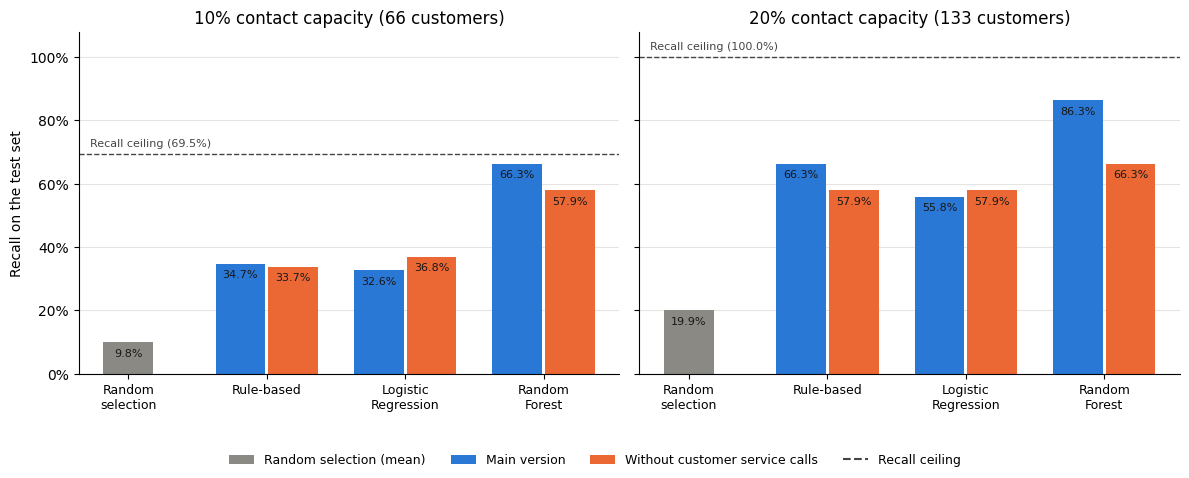

Saved reports/figures/final_01_test_recall.png


In [12]:
# === 5.1 Test recall by method and capacity ===
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

COLORS = {
    "shared": "#8a8984",
    "main": "#2a78d6",
    "without_service_calls": "#eb6834",
}
LABELS = {
    "shared": "Random selection (mean)",
    "main": "Main version",
    "without_service_calls": "Without customer service calls",
}
METHOD_LABELS = {
    "Random selection": "Random\nselection",
    "Rule-based": "Rule-based",
    "Logistic Regression": "Logistic\nRegression",
    "Random Forest": "Random\nForest",
}

bar_width = 0.38
positions = np.arange(len(METHOD_ORDER))

fig, axes = plt.subplots(
    1, len(CONTACT_CAPACITIES), figsize=(12, 4.8),
    sharey=True, squeeze=False,
)

for ax, capacity in zip(axes[0], CONTACT_CAPACITIES):
    subset = test_results_long.loc[
        np.isclose(test_results_long["capacity"], capacity)
    ]
    recalls = subset.set_index(["method", "version"])["recall"]

    for x, method in zip(positions, METHOD_ORDER):
        if method == "Random selection":
            bars = [("shared", 0.0)]
        else:
            bars = [
                ("main", -bar_width / 2),
                ("without_service_calls", bar_width / 2),
            ]

        for version, offset in bars:
            recall = recalls.loc[(method, version)]
            ax.bar(
                x + offset, recall, width=bar_width - 0.02,
                color=COLORS[version], zorder=2,
            )
            ax.annotate(
                f"{recall:.1%}", (x + offset, recall),
                xytext=(0, -4), textcoords="offset points",
                ha="center", va="top", fontsize=8, color="#171717",
            )

    n_contacts = int(subset["n_selected"].unique().item())
    ceiling = float(subset["recall_ceiling"].unique().item())

    ax.axhline(ceiling, color="#444444", linestyle="--", linewidth=1)
    ax.annotate(
        f"Recall ceiling ({ceiling:.1%})", (0.02, ceiling),
        xycoords=("axes fraction", "data"),
        xytext=(0, 4), textcoords="offset points",
        va="bottom", fontsize=8, color="#444444",
    )
    ax.set_title(f"{capacity:.0%} contact capacity ({n_contacts} customers)")
    ax.set_xticks(positions, [METHOD_LABELS[m] for m in METHOD_ORDER], fontsize=9)
    ax.set_ylim(0, 1.08)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0, 0].set_ylabel("Recall on the test set")

legend_handles = [
    Patch(facecolor=COLORS[version], label=LABELS[version])
    for version in ("shared", "main", "without_service_calls")
]
legend_handles.append(
    Line2D([0], [0], color="#444444", linestyle="--", label="Recall ceiling")
)
fig.legend(
    handles=legend_handles, loc="lower center",
    ncol=4, frameon=False, fontsize=9,
)
fig.tight_layout(rect=(0, 0.10, 1, 1))

recall_fig_path = FIGURES / "final_01_test_recall.png"
fig.savefig(recall_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {recall_fig_path.relative_to(PROJECT)}")

In [13]:
# === 5.2 Compute and check the cumulative gains curves ===
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

GAINS_METHODS = ("Rule-based", "Logistic Regression", "Random Forest")
GAINS_VERSIONS = ("main", "without_service_calls")

y_test_array = np.asarray(y_test)
n_test = len(y_test_array)
n_test_churners = int(y_test_array.sum())
contact_counts = np.arange(n_test + 1)
contact_share = contact_counts / n_test

capacity_contacts = {
    capacity: int(np.floor(capacity * n_test))
    for capacity in CONTACT_CAPACITIES
}

gains = {}
for method in GAINS_METHODS:
    for version in GAINS_VERSIONS:
        ranking = rank_positions(test_sort_keys[(method, version)])
        churners_captured = np.r_[0, np.cumsum(y_test_array[ranking])]
        curve = churners_captured / n_test_churners
        gains[(method, version)] = curve

        # Check that the curve agrees with the reported test recall.
        for capacity, n_contacts in capacity_contacts.items():
            reported_recall = test_results_long.loc[
                (test_results_long["method"] == method)
                & (test_results_long["version"] == version)
                & np.isclose(test_results_long["capacity"], capacity),
                "recall",
            ].item()

            if not np.isclose(curve[n_contacts], reported_recall):
                raise ValueError(
                    f"Gains and test recall differ for {method}, {version}, "
                    f"at {capacity:.0%} capacity."
                )

perfect_gains = np.minimum(contact_counts, n_test_churners) / n_test_churners
print(f"Gains curves match the reported test recall for all {len(gains)} versions.")

Gains curves match the reported test recall for all 6 versions.


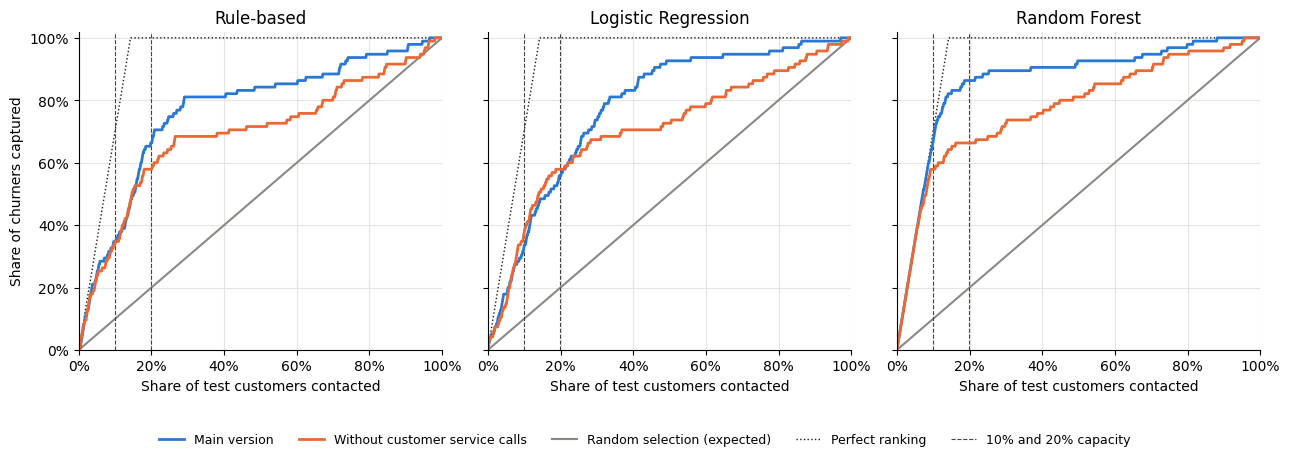

Saved reports/figures/final_02_gains_curves.png


In [14]:
# === 5.3 Plot the cumulative gains curves ===
fig, axes = plt.subplots(1, len(GAINS_METHODS), figsize=(13, 4.6), sharey=True)

for ax, method in zip(axes, GAINS_METHODS):
    ax.plot(contact_share, perfect_gains, color="#171717", linestyle=":", linewidth=1)
    ax.plot([0, 1], [0, 1], color=COLORS["shared"], linewidth=1.5)
    for n_contacts in capacity_contacts.values():
        ax.axvline(n_contacts / n_test, color="#444444", linestyle="--", linewidth=0.8)
    for version in GAINS_VERSIONS:
        ax.plot(contact_share, gains[(method, version)], color=COLORS[version], linewidth=2)

    ax.set_title(method)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Share of test customers contacted")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set_axisbelow(True)
    ax.grid(color="#e5e4e0", linewidth=0.8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0].set_ylabel("Share of churners captured")

legend_handles = [
    Line2D([0], [0], color=COLORS[version], linewidth=2, label=LABELS[version])
    for version in GAINS_VERSIONS
]
legend_handles.extend([
    Line2D([0], [0], color=COLORS["shared"], linewidth=1.5, label="Random selection (expected)"),
    Line2D([0], [0], color="#171717", linestyle=":", linewidth=1, label="Perfect ranking"),
    Line2D([0], [0], color="#444444", linestyle="--", linewidth=0.8, label="10% and 20% capacity"),
])
fig.legend(handles=legend_handles, loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.10, 1, 1))

gains_fig_path = FIGURES / "final_02_gains_curves.png"
fig.savefig(gains_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {gains_fig_path.relative_to(PROJECT)}")

### Visual findings

**Test recall.** At 10% contact capacity, the main Random Forest came
closest to the recall ceiling, capturing 66.3% of recorded churners
against a maximum of 69.5%. At 20% capacity, it captured 86.3%, a lead
of 20.0 percentage points over the next-highest result (66.3%). All
six ranked versions exceeded the mean recall of random selection at
both capacities.

**Cumulative gains.** The six curves stay above the expected
random-selection line across most of the contact range. The main
Random Forest rises steeply and captures about 90% of recorded
churners by the time roughly 30% of test customers are contacted.
Its two versions track each other closely at low contact levels.
The gap grows from 8.4 percentage points at 10% capacity to 20.0
points at 20% capacity.

The two rule-based curves are close at low contact levels, with a
larger gap in favour of the main version at 20% capacity. For
Logistic Regression, the version without `Customer service calls`
has slightly higher observed recall at both target capacities.
The curves cross shortly after the 20% contact mark, and the main
version leads over much of the remaining range. The paired bootstrap
intervals include zero at both target capacities, so the direction
of the recall difference there remains uncertain.

**Scope.** The gains curves describe rankings on the held-out test
set. Section 4 reports bootstrap intervals for the two prespecified
contact capacities, 10% and 20%. Patterns at other contact levels
are descriptive.

## 6. Model interpretation

This section examines which predictors Logistic Regression and Random
Forest rely on when ranking customers for retention contact. It covers
the main versions and the sensitivity versions without
`Customer service calls`.

Section 3 retained the test scores. For this analysis, each model is
refitted on the full development set using the same settings and
random seed. The predicted churn probabilities from the refitted models
are checked against the test scores retained in Section 3.

###  Permutation feature importance

For each fitted pipeline, one original predictor at a time is shuffled
across test customers. The fitted pipeline then scores the shuffled
data, and customers are ranked again. For each shuffle, the drop in the
equally weighted mean of `Recall@10%` and `Recall@20%` is calculated
relative to the same model's score on the unshuffled test set. This is
the same recall measure used for model tuning. A predictor's importance
is its mean recall drop over 30 shuffles, reported in percentage points.
For each predictor and repeat, all models that use that predictor are
evaluated on the same shuffled test data.

A larger positive value means that shuffling the predictor reduced the
recall measure more on average. A value near zero means that shuffling
produced little average change. A negative value means that the recall
measure was higher on average after shuffling on this test set.

Importance is reported only for predictors that each fitted pipeline
uses. Categorical predictors are shuffled before one-hot encoding, so
each original predictor receives one importance score per fitted
pipeline. Correlated predictors can provide similar information, which
can reduce their individual importance scores.

In [15]:
# === 6.1 Refit the final models and check them against Section 3 ===
from time import perf_counter

N_PERMUTATIONS = 30
test_labels = np.asarray(y_test)
test_churners = int(test_labels.sum())


def mean_recall(scores):
    """Return the equally weighted mean of recall at both contact capacities."""
    ranking = rank_positions([scores])
    recalls = [
        test_labels[ranking[:n_contacts]].sum() / test_churners
        for n_contacts in capacity_contacts.values()
    ]
    return float(np.mean(recalls))


final_models = {}
model_predictors = {}
baseline_recall = {}

for model_name, method in MODEL_NAMES.items():
    for version in VERSIONS:
        key = (method, version)
        pipeline = build_model(model_name, version).fit(X_dev, y_dev)

        scores = pipeline.predict_proba(X_test)[:, 1]
        stored_scores = test_sort_keys[key][0]

        if not np.allclose(scores, stored_scores):
            raise ValueError(
                f"Refitted {method} ({version}) scores differ from Section 3."
            )

        if not np.array_equal(
            rank_positions([scores]), rank_positions([stored_scores])
        ):
            raise ValueError(
                f"Refitted {method} ({version}) ranking differs from Section 3."
            )

        final_models[key] = pipeline
        baseline_recall[key] = mean_recall(scores)
        model_predictors[key] = {
            column
            for name, _, columns in pipeline.named_steps["preprocess"].transformers_
            if name in ("categorical", "numeric")
            for column in columns
        }

for (method, version), predictors in model_predictors.items():
    print(f"{method} ({version}): {len(predictors)} predictors")

Logistic Regression (main): 15 predictors
Logistic Regression (without_service_calls): 12 predictors
Random Forest (main): 14 predictors
Random Forest (without_service_calls): 13 predictors


In [16]:
# === 6.2 Compute permutation importance on the test set ===
permutation_rng = np.random.default_rng(RANDOM_SEED)
start = perf_counter()
pfi_rows = []

for repeat in range(1, N_PERMUTATIONS + 1):
    for predictor in X_test.columns:
        shuffled_positions = permutation_rng.permutation(len(X_test))
        X_permuted = X_test.copy()
        X_permuted[predictor] = X_test[predictor].iloc[shuffled_positions].array

        for key, pipeline in final_models.items():
            if predictor not in model_predictors[key]:
                continue

            method, version = key
            scores = pipeline.predict_proba(X_permuted)[:, 1]
            recall_drop = baseline_recall[key] - mean_recall(scores)

            pfi_rows.append({
                "method": method,
                "version": version,
                "predictor": predictor,
                "repeat": repeat,
                "importance_pp": 100 * recall_drop,
            })

    if repeat % 10 == 0:
        elapsed = perf_counter() - start
        print(f"{repeat}/{N_PERMUTATIONS} repeats completed ({elapsed:.0f} s)")

pfi_long = pd.DataFrame(pfi_rows)
print(f"Rows: {len(pfi_long):,} | Model versions: {len(final_models)}")

10/30 repeats completed (13 s)
20/30 repeats completed (27 s)
30/30 repeats completed (40 s)
Rows: 1,620 | Model versions: 4


In [17]:
# === 6.3 Summarise permutation importance ===
group_columns = ["method", "version", "predictor"]

# Check that each model has the expected predictors and repeat IDs.
expected_groups = {
    (method, version, predictor)
    for (method, version), predictors in model_predictors.items()
    for predictor in predictors
}
repeat_groups = pfi_long.groupby(group_columns, dropna=False)["repeat"]
actual_groups = set(repeat_groups.size().index)
expected_repeats = set(range(1, N_PERMUTATIONS + 1))

if actual_groups != expected_groups:
    raise ValueError("Unexpected or missing model, version or predictor groups.")

for key, repeats in repeat_groups:
    if len(repeats) != N_PERMUTATIONS or set(repeats) != expected_repeats:
        raise ValueError(f"Missing, duplicated or invalid repeats for {key}.")

# Summarise the recall drop in percentage points.
pfi_summary = (
    pfi_long.groupby(group_columns, as_index=False)["importance_pp"]
    .agg(mean_importance_pp="mean", sd_importance_pp="std")
)

pfi_summary["rank"] = (
    pfi_summary.groupby(["method", "version"])["mean_importance_pp"]
    .rank(ascending=False, method="min")
    .astype(int)
)
pfi_summary = pfi_summary.sort_values(
    ["method", "version", "rank", "predictor"]
).reset_index(drop=True)

pfi_path = TABLES / "final_permutation_importance.csv"
pfi_summary.to_csv(pfi_path, index=False)

# Compare model versions side by side.
pfi_wide = pfi_summary.pivot(
    index="predictor",
    columns=["method", "version"],
    values="mean_importance_pp",
)
model_columns = pd.MultiIndex.from_tuples(
    list(final_models), names=["method", "version"]
)
pfi_wide = pfi_wide.reindex(columns=model_columns)
pfi_wide = pfi_wide.sort_values(("Random Forest", "main"), ascending=False)

pfi_display = pfi_wide.round(1).astype(object).where(pfi_wide.notna(), "not used")
display(pfi_display)
print(f"Saved {pfi_path.relative_to(PROJECT)}")

method                 Logistic Regression                        \
version                               main without_service_calls   
predictor                                                          
Total day minutes                      7.1                  20.9   
Customer service calls                 4.8              not used   
International plan                     5.5                   6.8   
Total eve minutes                      2.4                   6.4   
Voice mail plan                        1.9              not used   
Total intl minutes                     0.1                  -0.8   
Total intl calls                      -1.4                  -1.1   
Total night minutes                    0.5                   0.5   
Number vmail messages                  0.1                   5.8   
Total day calls                        0.5                   0.0   
Account length                        -0.2                  -0.2   
Area code                              0.7                   0.0   
Total eve calls                        0.0                  -0.1   
Total night calls                      0.3                  -0.1   
State                                 -0.8              not used   

method                 Random Forest                        
version                         main without_service_calls  
predictor                                                   
Total day minutes               35.7                  34.4  
Customer service calls          19.3              not used  
International plan              11.1                  10.7  
Total eve minutes                9.4                   7.4  
Voice mail plan                  5.7                   5.6  
Total intl minutes               4.6                   2.9  
Total intl calls                 4.1                   2.2  
Total night minutes              1.7                   2.1  
Number vmail messages            0.2                   1.4  
Total day calls                  0.1                   0.2  
Account length                  -0.0                   0.1  
Area code                       -0.1                  -0.1  
Total eve calls                 -0.1                   0.0  
Total night calls               -0.2                  -0.7  
State                       not used              not used

Saved reports/tables/final_permutation_importance.csv


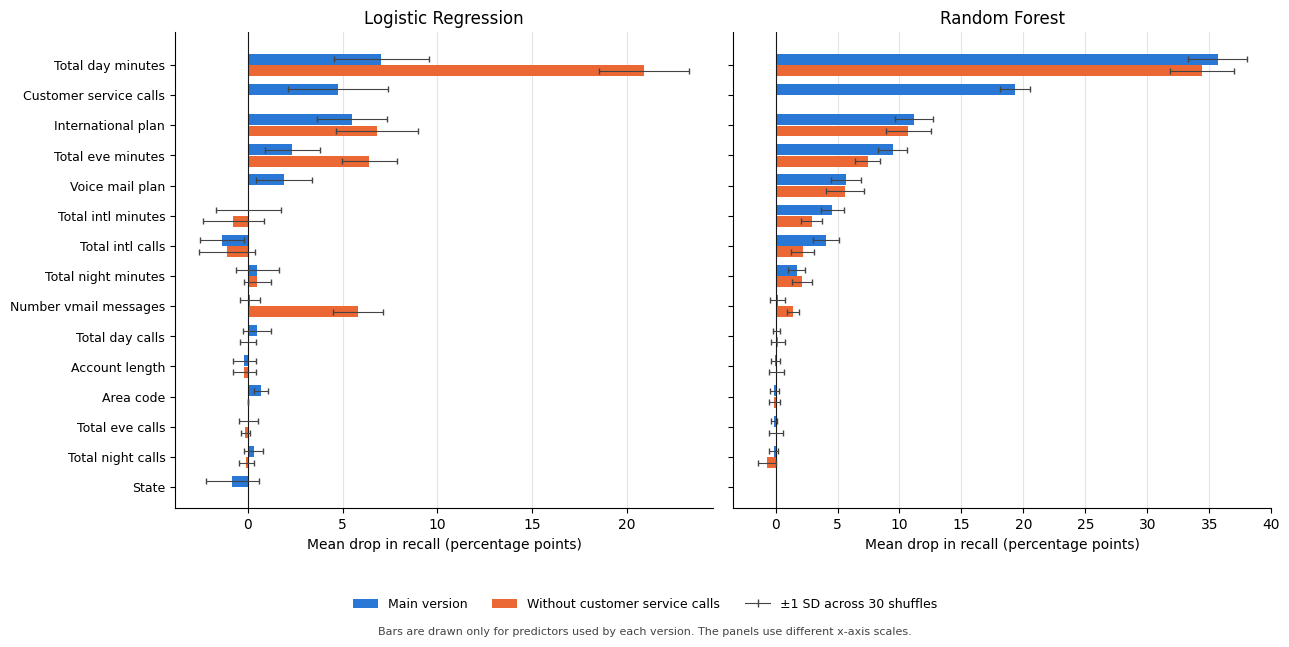

Saved reports/figures/final_03_permutation_importance.png


In [18]:
# === 6.4 Plot permutation importance ===
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

predictor_order = list(reversed(pfi_wide.index))
y_positions = np.arange(len(predictor_order))
bar_height = 0.38

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)

for ax, method in zip(axes, ("Logistic Regression", "Random Forest")):
    for version, offset in (
        ("main", bar_height / 2),
        ("without_service_calls", -bar_height / 2),
    ):
        values = (
            pfi_summary.loc[
                (pfi_summary["method"] == method)
                & (pfi_summary["version"] == version)
            ]
            .set_index("predictor")
            .reindex(predictor_order)
        )

        # Draw bars only for predictors used by this model version.
        used = values["mean_importance_pp"].notna().to_numpy()
        ax.barh(
            y_positions[used] + offset,
            values.loc[used, "mean_importance_pp"],
            height=bar_height - 0.02,
            xerr=values.loc[used, "sd_importance_pp"],
            color=COLORS[version],
            zorder=2,
            error_kw={"ecolor": "#444444", "elinewidth": 0.8, "capsize": 2},
        )

    ax.axvline(0, color="#171717", linewidth=0.8)
    ax.set_title(method)
    ax.set_xlabel("Mean drop in recall (percentage points)")
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0].set_yticks(y_positions, predictor_order, fontsize=9)

legend_handles = [
    Patch(facecolor=COLORS["main"], label=LABELS["main"]),
    Patch(
        facecolor=COLORS["without_service_calls"],
        label=LABELS["without_service_calls"],
    ),
    Line2D(
        [0], [0], color="#444444", linewidth=0.8,
        marker="|", label="±1 SD across 30 shuffles",
    ),
]
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),
    ncol=3,
    frameon=False,
    fontsize=9,
)
fig.text(
    0.5, 0.015,
    "Bars are drawn only for predictors used by each version. "
    "The panels use different x-axis scales.",
    ha="center",
    fontsize=8,
    color="#444444",
)
fig.tight_layout(rect=(0, 0.12, 1, 1))

pfi_fig_path = FIGURES / "final_03_permutation_importance.png"
fig.savefig(pfi_fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {pfi_fig_path.relative_to(PROJECT)}")

### Permutation importance findings

**Daytime usage.** `Total day minutes` ranked first in all four model
versions. Shuffling it reduced the equally weighted mean of
`Recall@10%` and `Recall@20%` by 35.7 percentage points in the main
Random Forest and by 34.4 points in the version without
`Customer service calls`. The corresponding drops for Logistic
Regression were 7.1 and 20.9 points. When comparing these absolute
drops across models, the unshuffled recall provides context. The
main Logistic Regression started at 44.2% mean recall across the two
capacities, while the main Random Forest started at 76.3%.

**Customer service calls and other predictors.** Shuffling
`Customer service calls` reduced mean recall by 19.3 points in the
main Random Forest and by 4.8 points in the main Logistic Regression.
The three highest-ranked predictors in the main Random Forest were
`Total day minutes`, `Customer service calls` and `International plan`,
the same three predictors used in the rule-based approach.
`International plan` and `Total eve minutes` had positive mean
importance in all four versions. In Logistic Regression,
`Number vmail messages` had a mean importance of 5.8 points in the
sensitivity version and 0.1 points in the main version. The sensitivity
version also excluded `Voice mail plan`.

**Variation and interpretation.** The error bars show one standard
deviation on either side of the mean across 30 shuffles of each
predictor on the same test set. A negative importance value, such as
−1.4 points for `Total intl calls` in the main Logistic Regression,
means that mean recall was slightly higher after shuffling. The
importance scores describe how the fitted pipelines relied on each
predictor when ranking test customers at the two contact capacities.
The timing of `Customer service calls` relative to churn remains
undocumented, so its availability at prediction time is uncertain.

### SHAP explanations for the main Random Forest

Permutation importance measures how much mean recall changes when a
predictor is shuffled. SHAP shows how each predictor contributes to
an individual customer's predicted churn probability. This analysis
focuses on the main Random Forest, which achieved the highest test
recall at both contact capacities. SHAP values are calculated for all
667 test customers.

Each customer's explanation starts from the SHAP base value, which
is the reference prediction used by the explainer. A positive SHAP
value contributes to a higher predicted churn probability relative
to that reference. A negative value contributes to a lower probability.
The code checks that the base value plus the sum of the SHAP values
reproduces each customer's predicted churn probability within a
numerical tolerance.

The tree-based explainer uses the inputs produced by the fitted
preprocessing pipeline. For each original categorical predictor, the
SHAP values of its one-hot encoded columns are summed for each
customer. This gives one contribution per original predictor and
allows the results to be discussed using the same predictor names
as the permutation importance analysis.

SHAP values explain the fitted model's predictions. The effect of
changing a predictor on actual customer churn would require separate
evidence. The permutation importance analysis covers both model types
and both feature-set versions.

In [19]:
# === 6.5 Encode the test data and map columns to predictors ===
from time import perf_counter

import shap
from scipy import sparse

shap_key = ("Random Forest", "main")
shap_pipeline = final_models[shap_key]
preprocess = shap_pipeline.named_steps["preprocess"]
forest = shap_pipeline.named_steps["model"]

X_test_encoded = preprocess.transform(X_test)
if sparse.issparse(X_test_encoded):
    X_test_encoded = X_test_encoded.toarray()

# Match encoded columns to the original predictors used in Section 6.3.
column_to_predictor = np.empty(X_test_encoded.shape[1], dtype=object)
column_to_predictor[:] = None

for name, transformer, columns in preprocess.transformers_:
    if name == "categorical":
        # The fitted encoder in this pipeline keeps one column per category.
        if transformer.drop is not None or transformer.min_frequency is not None or (
            transformer.max_categories is not None
        ):
            raise ValueError("Update the SHAP mapping for the configured encoder.")

        predictors = [
            column
            for column, categories in zip(columns, transformer.categories_)
            for _ in categories
        ]
    elif name == "numeric":
        predictors = list(columns)
    else:
        continue

    output_slice = preprocess.output_indices_[name]
    if len(predictors) != output_slice.stop - output_slice.start:
        raise ValueError(f"Unexpected number of encoded columns for {name}.")

    column_to_predictor[output_slice] = predictors

if set(column_to_predictor) != model_predictors[shap_key]:
    raise ValueError("SHAP column mapping does not match the fitted predictors.")

print(f"Encoded test data: {X_test_encoded.shape[0]} customers x "
      f"{X_test_encoded.shape[1]} columns from {len(model_predictors[shap_key])} predictors")

Encoded test data: 667 customers x 18 columns from 14 predictors


In [20]:
# === 6.6 Compute and check SHAP values for the main Random Forest ===
# Select the SHAP output for the churn class.
churn_class_index = np.flatnonzero(forest.classes_ == 1).item()

start = perf_counter()
explainer = shap.TreeExplainer(forest)
raw_values = explainer.shap_values(X_test_encoded)

if isinstance(raw_values, list):
    encoded_shap = np.asarray(raw_values[churn_class_index])
else:
    raw_values = np.asarray(raw_values)
    expected_shape = (*X_test_encoded.shape, len(forest.classes_))
    if raw_values.shape != expected_shape:
        raise ValueError(f"Unexpected SHAP output shape {raw_values.shape}.")
    encoded_shap = raw_values[:, :, churn_class_index]

if encoded_shap.shape != X_test_encoded.shape:
    raise ValueError("The SHAP matrix does not match the encoded test data.")

base_value = float(np.ravel(explainer.expected_value)[churn_class_index])

# Sum encoded contributions within each original predictor.
shap_values = (
    pd.DataFrame(encoded_shap, index=X_test.index)
    .T.groupby(column_to_predictor, sort=False)
    .sum()
    .T
)

# Verify that grouped contributions reconstruct churn probabilities.
predicted = shap_pipeline.predict_proba(X_test)[:, churn_class_index]
reconstructed = base_value + shap_values.sum(axis=1).to_numpy()
max_gap = float(np.max(np.abs(reconstructed - predicted)))

if not np.isfinite(max_gap) or max_gap > 1e-6:
    raise ValueError(
        f"Grouped SHAP values do not reproduce churn probabilities "
        f"(max gap {max_gap:.2e})."
    )

print(f"SHAP values computed in {perf_counter() - start:.0f} s")
print(f"Base value: {base_value:.3f}")
print(f"Additivity check passed (max gap {max_gap:.1e})")
print(f"SHAP matrix: {shap_values.shape[0]} customers x {shap_values.shape[1]} predictors")

SHAP values computed in 9 s
Base value: 0.145
Additivity check passed (max gap 1.9e-14)
SHAP matrix: 667 customers x 14 predictors


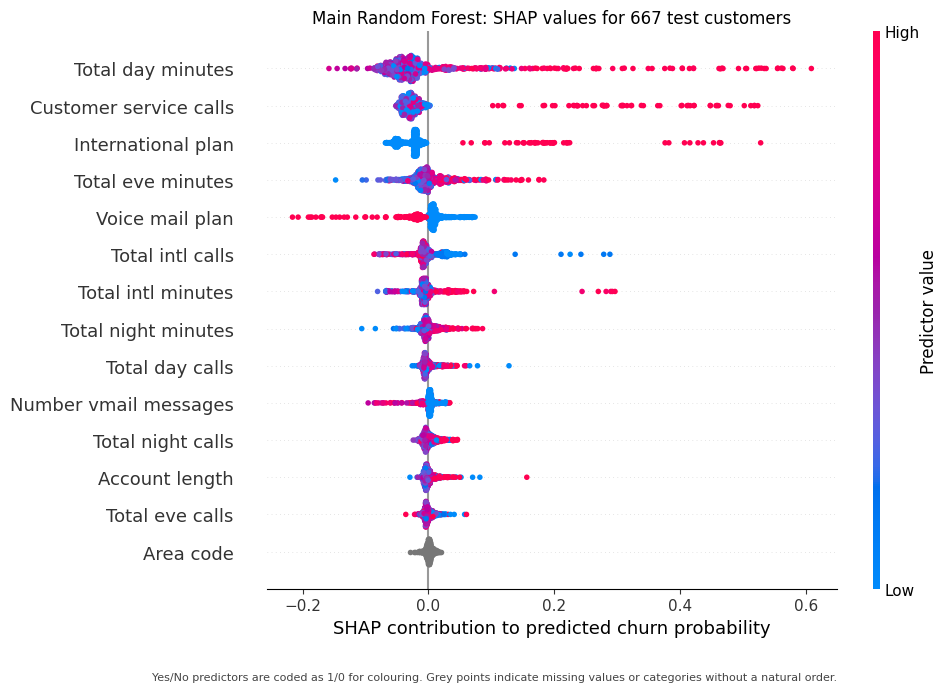

,predictor,mean_abs_shap
0,Total day minutes,0.071
1,Customer service calls,0.054
2,International plan,0.045
3,Total eve minutes,0.022
4,Voice mail plan,0.019
5,Total intl calls,0.017
6,Total intl minutes,0.016
7,Total night minutes,0.011
8,Total day calls,0.008
9,Number vmail messages,0.008


Saved reports/figures/final_04_shap_summary.png
Saved reports/tables/final_shap_mean_abs.csv


In [21]:
# === 6.7 Plot SHAP values for the main Random Forest ===
import warnings

import matplotlib.pyplot as plt

mean_abs_shap = shap_values.abs().mean().sort_values(ascending=False)
shap_order = mean_abs_shap.index.tolist()

categorical_predictors = {
    column
    for name, _, columns in preprocess.transformers_
    if name == "categorical"
    for column in columns
}

# Align feature values with the rows and columns of the SHAP matrix.
test_features = X_test.loc[shap_values.index, shap_order]
feature_values = pd.DataFrame(index=shap_values.index)

for predictor in shap_order:
    column = test_features[predictor]

    if predictor not in categorical_predictors:
        feature_values[predictor] = column.to_numpy(dtype=float, na_value=np.nan)
        continue

    labels = column.astype("string").str.strip().str.casefold()
    observed_labels = set(labels.dropna())

    if observed_labels and observed_labels <= {"yes", "no"}:
        feature_values[predictor] = labels.map({"yes": 1.0, "no": 0.0}).astype(float)
    else:
        feature_values[predictor] = np.nan

plt.figure()
with warnings.catch_warnings():
    # Area code is intentionally all-NaN for colouring, which triggers a harmless warning.
    warnings.simplefilter("ignore", RuntimeWarning)
    shap.summary_plot(
        shap_values[shap_order].to_numpy(),
        features=feature_values[shap_order],
        feature_names=shap_order,
        max_display=len(shap_order),
        sort=False,
        show=False,
        plot_size=(10, 7),
        color_bar_label="Predictor value",
    )

fig = plt.gcf()
ax = fig.axes[0]
ax.set_xlabel("SHAP contribution to predicted churn probability")
ax.set_title(f"Main Random Forest: SHAP values for {len(shap_values):,} test customers")

fig.text(
    0.5, 0.02,
    "Yes/No predictors are coded as 1/0 for colouring. "
    "Grey points indicate missing values or categories without a natural order.",
    ha="center",
    fontsize=8,
    color="#444444",
)
fig.tight_layout(rect=(0, 0.06, 1, 1))

shap_fig_path = FIGURES / "final_04_shap_summary.png"
fig.savefig(shap_fig_path, dpi=300, bbox_inches="tight")
plt.show()

shap_summary = (
    mean_abs_shap.rename("mean_abs_shap")
    .rename_axis("predictor")
    .reset_index()
)
shap_summary_path = TABLES / "final_shap_mean_abs.csv"
shap_summary.to_csv(shap_summary_path, index=False)

display(shap_summary.round(3))
print(f"Saved {shap_fig_path.relative_to(PROJECT)}")
print(f"Saved {shap_summary_path.relative_to(PROJECT)}")

### SHAP findings

**Ranking of predictors.** Across the 667 test customers, the five
highest-ranked predictors by mean absolute SHAP value were `Total day
minutes` (0.071), `Customer service calls` (0.054), `International plan`
(0.045), `Total eve minutes` (0.022) and `Voice mail plan` (0.019).
Permutation importance ranked the same five predictors in the same
order for the main Random Forest. `Area code` had the lowest mean
absolute SHAP value (0.003). For `Total day minutes`, a value of 0.071
means that the average magnitude of its contribution was 7.1
percentage points on the predicted churn probability scale.

**Direction of contributions.** High values of `Total day minutes`
were associated with large positive SHAP contributions for some
customers, reaching about 0.60. Lower values tended to have smaller
contributions near or below zero. Most contributions from `Customer
service calls` were near zero or slightly negative, while a group
with high call counts had clearly positive contributions.

Having an `International plan` generally contributed positively to
predicted churn probability. Having a `Voice mail plan` generally
contributed negatively, and higher values of `Number vmail messages`
showed a similar pattern. Higher values of evening, night and
international minutes tended to contribute positively, with smaller
average magnitudes than daytime minutes. A few customers with low
`Total intl calls` had positive contributions approaching 0.30.

**Interpretation.** The concentration of large positive contributions
among some customers with high daytime usage or many service calls is
consistent with non-linear patterns learned by the Random Forest.
The summary plot describes how the fitted model used these predictors
on the held-out test set. The specific patterns behind the Random
Forest's recall advantage over Logistic Regression would require
further analysis. The timing of `Customer service calls` relative to
churn is undocumented, so its availability at prediction time remains
uncertain.

## 7. Summary and outputs

**Test performance.** The main Random Forest achieved the highest test
recall at both contact capacities. It identified 63 of 95 churners at
10% capacity (66.3% recall), close to the maximum achievable recall
of 69.5%, and 82 of 95 at 20% capacity (86.3% recall). Across both
feature-set versions and both capacities, Random Forest had higher
recall than the corresponding rule-based and Logistic Regression
versions. All eight paired 95% bootstrap intervals for these
comparisons were above zero. All six ranked versions also exceeded
the mean recall of random selection at both capacities.

**Sensitivity to `Customer service calls`.** Random Forest retained
the highest recall at both capacities after this predictor was
excluded and the model was retuned. Its recall fell by 8.4 percentage
points at 10% capacity and by 20.0 points at 20% capacity. At 20%
capacity, its lead over each alternative narrowed to 8.4 points.
The lower bounds of the paired intervals were 1.2 points against
the rule-based approach and 2.0 points against Logistic Regression.
The timing of service calls relative to churn is undocumented, so
the sensitivity analysis shows how much performance depends on
including this potentially unavailable predictor.

**Model interpretation.** `Total day minutes` ranked first by
permutation importance in all four fitted model versions. In the
main Random Forest, `Total day minutes`, `Customer service calls`
and `International plan` were the three highest-ranked predictors
by both permutation importance and mean absolute SHAP value. The
rule-based approach used the same three predictors. Higher daytime
usage, more service calls and having an international plan generally
contributed to higher predicted churn probabilities. Having a
voicemail plan generally contributed to lower predicted probabilities.

**Limitations.** The evaluation used one held-out test set with 95
recorded churners from a single dataset. The bootstrap intervals
reflect variation from resampling those test customers while holding
the fitted models and rule thresholds fixed. Permutation importance
and SHAP describe the fitted models. Estimating the effect of a
retention contact on actual churn would require intervention data.

**Saved outputs**

| Type | File | Content |
|---|---|---|
| Table | `final_test_results.csv` | Test recall and lift by method, version and capacity, plus average precision and ROC AUC for the fitted models |
| Table | `final_bootstrap_recall_intervals.csv` | Bootstrap intervals for test recall |
| Table | `final_bootstrap_difference_intervals.csv` | Bootstrap intervals for paired recall differences |
| Table | `final_permutation_importance.csv` | Permutation importance by model version and predictor |
| Table | `final_shap_mean_abs.csv` | Mean absolute SHAP values for the main Random Forest |
| Figure | `final_01_test_recall.png` | Test recall by method and capacity |
| Figure | `final_02_gains_curves.png` | Cumulative gains curves |
| Figure | `final_03_permutation_importance.png` | Permutation importance |
| Figure | `final_04_shap_summary.png` | SHAP summary plot |

Tables are saved in `reports/tables/` and figures in `reports/figures/`.

In [22]:
# === 7.1 Check the saved outputs ===
expected_outputs = [
    TABLES / "final_test_results.csv",
    TABLES / "final_bootstrap_recall_intervals.csv",
    TABLES / "final_bootstrap_difference_intervals.csv",
    TABLES / "final_permutation_importance.csv",
    TABLES / "final_shap_mean_abs.csv",
    FIGURES / "final_01_test_recall.png",
    FIGURES / "final_02_gains_curves.png",
    FIGURES / "final_03_permutation_importance.png",
    FIGURES / "final_04_shap_summary.png",
]

output_rows = []

for path in expected_outputs:
    relative_path = path.relative_to(PROJECT)

    if not path.is_file():
        raise FileNotFoundError(f"Missing output file: {relative_path}")

    size_bytes = path.stat().st_size
    if size_bytes == 0:
        raise ValueError(f"Empty output file: {relative_path}")

    output_rows.append({
        "file": relative_path.as_posix(),
        "size_kib": round(size_bytes / 1024, 1),
    })

output_check = pd.DataFrame(output_rows)
display(output_check)

print(
    f"Verified {len(output_check)} output files. "
    "All are present and non-empty."
)

,file,size_kib
0,reports/tables/final_test_results.csv,1.6
1,reports/tables/final_bootstrap_recall_interval...,1.1
2,reports/tables/final_bootstrap_difference_inte...,1.7
3,reports/tables/final_permutation_importance.csv,4.7
4,reports/tables/final_shap_mean_abs.csv,0.5
5,reports/figures/final_01_test_recall.png,192.1
6,reports/figures/final_02_gains_curves.png,314.1
7,reports/figures/final_03_permutation_importanc...,226.4
8,reports/figures/final_04_shap_summary.png,424.8


Verified 9 output files. All are present and non-empty.
